In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xtrack as xt
import xcoll as xc
import xpart as xp
import xobjects as xo
import sys
import gzip, json

In [2]:
def version_larger_or_equal_than(ver1, ver2):
    ver1 = sum([int(v)*10**(3*(2-i)) for i,v in enumerate(ver1.split('.'))])
    ver2 = sum([int(v)*10**(3*(2-i)) for i,v in enumerate(ver2.split('.'))])
    return ver1 >= ver2

def remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2):
    "Remove apertures of off-momentum BPMs which give flanges as bottlenecks"
    tt = line.get_table()
    tw = line.twiss()
    mask_disp = 5*np.sqrt(tw.betx*exn*pmass/nrj)+n_buckets*bucket_height*tw.dx > 0.025
    mask_bpm = ['bp' in name for name in tt.name]
    mask_aper = np.array(['aper' in name for name in tt.name])
    offmom_bpms = tt.name[mask_disp & mask_bpm & ~mask_aper]
    aper_to_remove = [f'{name}{suffix}' for name in offmom_bpms for suffix in ('.a_aper', '.b_aper')]
    line.remove(aper_to_remove)

def install_tidp(line, block_mvt=29e-3):
    tidp_ap_tot = 147e-3
    line.discard_tracker()
    material = xc.materials.CarbonFibreCarbon if version_larger_or_equal_than(xc.__version__, '0.10.1') else xc.materials.Carbon
    tidp = xc.EverestCollimator(length=4.3, material=material, jaw_L= tidp_ap_tot/2 + block_mvt, jaw_R = -tidp_ap_tot/2 + block_mvt)
    line.xcoll.collimators.install(names=['tidp.11434'], elements=[tidp])
    return tidp

def install_tcsm(line, gap=5):
    material = xc.materials.CarbonFibreCarbon if version_larger_or_equal_than(xc.__version__, '0.10.1') else xc.materials.Carbon # in 0.6.8, materials are classes, in 0.10.1 they are instances
    line.discard_tracker()
    tcsm = xc.EverestCollimator(length=1.83, gap=gap, material=material) # length is 1.83
    line.xcoll.collimators.install(names=['tcsm.51932'], elements=[tcsm])

In [3]:
# Parameters
qx = 20.13
qy = 20.18
xi_x = 0.5
xi_y = 0.5

num_particles = 10000
num_turns = 3000
plane = 'H'
start_at_turn= 500
nemitt_x = 2e-6
nemitt_y = 2e-6
ramping_turns = 100
use_individual_kicks = True
coll_gap = 5

amplitude_adt = 0.095

In [4]:
#Line setup
line = xt.load('../sps_with_aperture_inj_q20_beam_sagitta4.json')
env = line.env
tt = line.get_table()

remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2)
tidp = install_tidp(line, block_mvt=29e-3)
tcsm = install_tcsm(line)

adt = xc.BlowUp.install(line, name=f'adt_{plane}_blowup', at=tt['s', 'adkcv.32171'], plane=plane, stop_at_turn=num_turns,
                        amplitude=amplitude_adt, use_individual_kicks=use_individual_kicks, start_at_turn=start_at_turn)

tw = line.twiss()
line.xcoll.collimators.assign_optics(twiss=tw, nemitt_x=nemitt_x, nemitt_y=nemitt_y)

Loading line from dict:   0%|          | 0/36381 [00:00<?, ?it/s]

/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:801: FutureWarning: `lag` (in degrees) is deprecated and will be removed in a future version. Please use `phase` (in radians) instead. If you see this warning while loading a saved line from a previous version of Xsuite, please regenerate the line with the current version to use phase instead of lag. Note that if both `lag` and `phase` are set, the effect is the sum of the two,  with `lag` converted to radians.  This deprecation is part of the interface cleanup in view of the 1.0 release.
  self.lag = lag
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam_elements/elements.py:3797: FutureWarning: `pn` (in degrees) is deprecated and will be removed in a future version. Please use `phase_n` (in radians) instead. Note that if both `pn` and `phase_n` are set, the effect is the sum of the two with `pn` converted to radians.
  self._warn_if_deprecated_phase_is_nonzero(pn, 'pn', 'phase_n')
/Users/lisepauwels/Xsuite/xtrack/xtrack/beam

Done loading line from dict.           


Slicing line:   0%|          | 0/32244 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/32242 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/32242 [00:00<?, ?it/s]

In [5]:
part = xp.generate_matched_gaussian_bunch(nemitt_x=nemitt_x,
                                          nemitt_y=nemitt_y,
                                          sigma_z=0.224, num_particles=num_particles, line=line)

*** Maximum RMS bunch length 0.23336637813369318m.
... distance to target bunch length: -2.2228e-01
... distance to target bunch length: 4.5424e-03
... distance to target bunch length: 4.3382e-03
... distance to target bunch length: -6.6565e-03
... distance to target bunch length: 2.0203e-03
... distance to target bunch length: -5.7185e-04
... distance to target bunch length: 1.0779e-04
... distance to target bunch length: 4.7891e-06
... distance to target bunch length: -2.0504e-09
... distance to target bunch length: 9.6490e-08
--> Bunch length: 0.22399999794961267
--> Emittance: 0.34347718864378546


In [6]:
line.discard_tracker()
line.build_tracker(_context=xo.ContextCpu(omp_num_threads='12'))
adt.calibrate_by_emittance(nemitt=nemitt_x, twiss=tw)
line.xcoll.scattering.enable()
adt.activate()
line.track(part, num_turns=num_turns, with_progress=True)
adt.deactivate()
line.xcoll.scattering.disable()

Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored


Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll/lib' ignored


Tracking:   0%|          | 0/3000 [00:00<?, ?it/s]

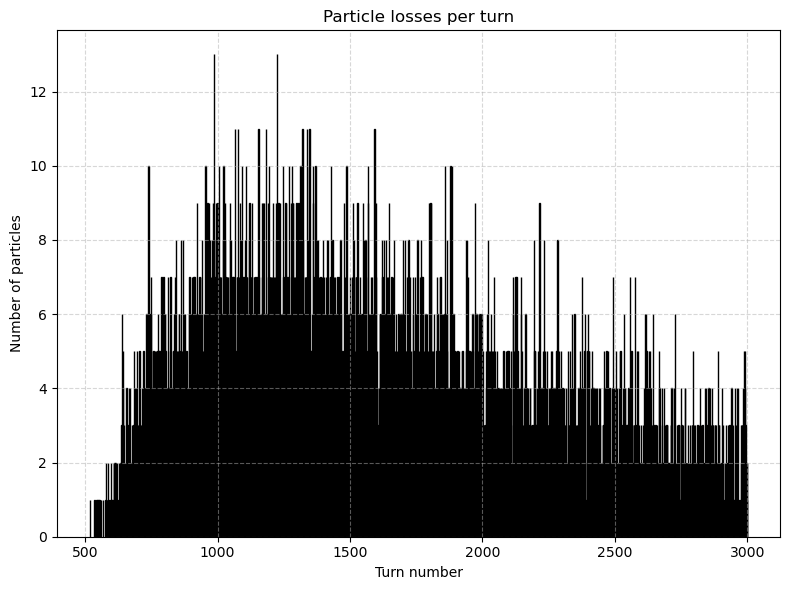

In [7]:
plt.close('all')
mask = part.state > 0
unique_turns, counts = np.unique(part.at_turn[~mask], return_counts=True)

fig, ax = plt.subplots(figsize=(8, 6))
# Plot histogram-like bar chart
ax.bar(unique_turns, counts, width=1.0, edgecolor='black')
ax.set_xlabel("Turn number")
ax.set_ylabel("Number of particles")
ax.set_title("Particle losses per turn")
ax.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
# plt.savefig(f'plots/adt_ramping/scheme1_10000part.png', dpi=300)
plt.show()

In [9]:
np.unique(part.state, return_counts=True)

(array([-330,    0,    1]), array([5724, 2527, 1749]))